In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#read dataset as pandas dataframe
sleep_df = pd.read_csv('sleep_data.csv')
sleep_df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
#checking brief information of dataset
sleep_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [4]:
#cleaning data columns

sleep_df['Sleep Disorder'] = sleep_df['Sleep Disorder'].fillna('No disorder')

sleep_df[['Systolic', 'Diastolic']] = sleep_df['Blood Pressure'].str.split('/', expand=True)
sleep_df[['Systolic', 'Diastolic']] = sleep_df[['Systolic', 'Diastolic']].astype('int64')
sleep_df[['Systolic', 'Diastolic']].dtypes

sleep_df['BMI Category'] = sleep_df['BMI Category'].str.replace("Normal Weight", 'Normal')
sleep_df['BMI Category'].unique()

array(['Overweight', 'Normal', 'Obese'], dtype=object)

In [5]:
#viewing unique values in each data columns
for c in sleep_df.columns:
    print(c)
    print('\n',sleep_df[c].unique())

Person ID

 [  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180
 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198
 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216
 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234
 235 236 237 238 239 240 241 242 243 24

In [6]:
#check for the number of unique ages in the age category
print('Count of unique ages :', sleep_df['Age'].unique())

print('\n')
#check for the unique ages in the age category
print('unique ages :', sleep_df['Age'].unique())

#Explore the Age column using the describe function
print(sleep_df['Age'].describe())

print('\n')

#create bins for the various age categories
twenty_fifth = sleep_df['Age'].quantile(0.25)
median = sleep_df['Age'].median()
seventy_fifth = sleep_df['Age'].quantile(0.75)
maximum = sleep_df['Age'].max()

#create a label and bins for the various age categories
labels = ['young_adult','middle_age','older_adult','elderlies']
bins = [0, twenty_fifth, median, seventy_fifth, maximum]

#create a category column for age
sleep_df['Age_cat'] = pd.cut(sleep_df['Age'], labels=labels, bins=bins)

Count of unique ages : 31


unique ages : [27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 48 49 50 51 52
 53 54 55 56 57 58 59]
count    374.000000
mean      42.184492
std        8.673133
min       27.000000
25%       35.250000
50%       43.000000
75%       50.000000
max       59.000000
Name: Age, dtype: float64




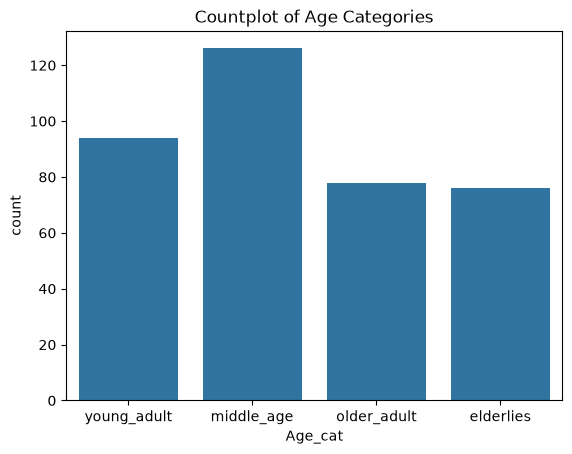

In [7]:
#sns.set_style('dark')
#sns.set_palette("Blues")
#visualization of the Age_cat column
sns.countplot(x='Age_cat',data=sleep_df)
plt.title('Countplot of Age Categories')
plt.show()

In [8]:
#check for duplicates
sleep_df.duplicated().sum()

np.int64(0)

In [9]:
sleep_df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic,Age_cat
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,No disorder,126,83,young_adult
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,No disorder,125,80,young_adult
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,No disorder,125,80,young_adult
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90,young_adult
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90,young_adult


In [10]:
sleep_df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920,128.553476,84.649733
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679,7.748118,6.161611
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000,115.000000,75.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000,125.000000,80.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000,130.000000,85.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000,135.000000,90.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000,142.000000,95.000000


In [11]:
sleep_df.describe(exclude=[np.number])

,Gender,Occupation,BMI Category,Blood Pressure,Sleep Disorder,Age_cat
count,374,374,374,374,374,374
unique,2,11,3,25,3,4
top,Male,Nurse,Normal,130/85,No disorder,middle_age
freq,189,73,216,99,219,126


In [12]:
num = sleep_df.select_dtypes(exclude=['object','category'])
#num.drop('Daily Steps', axis=1, inplace=True)
num

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic
0,1,27,6.1,6,42,6,77,4200,126,83
1,2,28,6.2,6,60,8,75,10000,125,80
2,3,28,6.2,6,60,8,75,10000,125,80
3,4,28,5.9,4,30,8,85,3000,140,90
4,5,28,5.9,4,30,8,85,3000,140,90
...,...,...,...,...,...,...,...,...,...,...
369,370,59,8.1,9,75,3,68,7000,140,95
370,371,59,8.0,9,75,3,68,7000,140,95
371,372,59,8.1,9,75,3,68,7000,140,95
372,373,59,8.1,9,75,3,68,7000,140,95


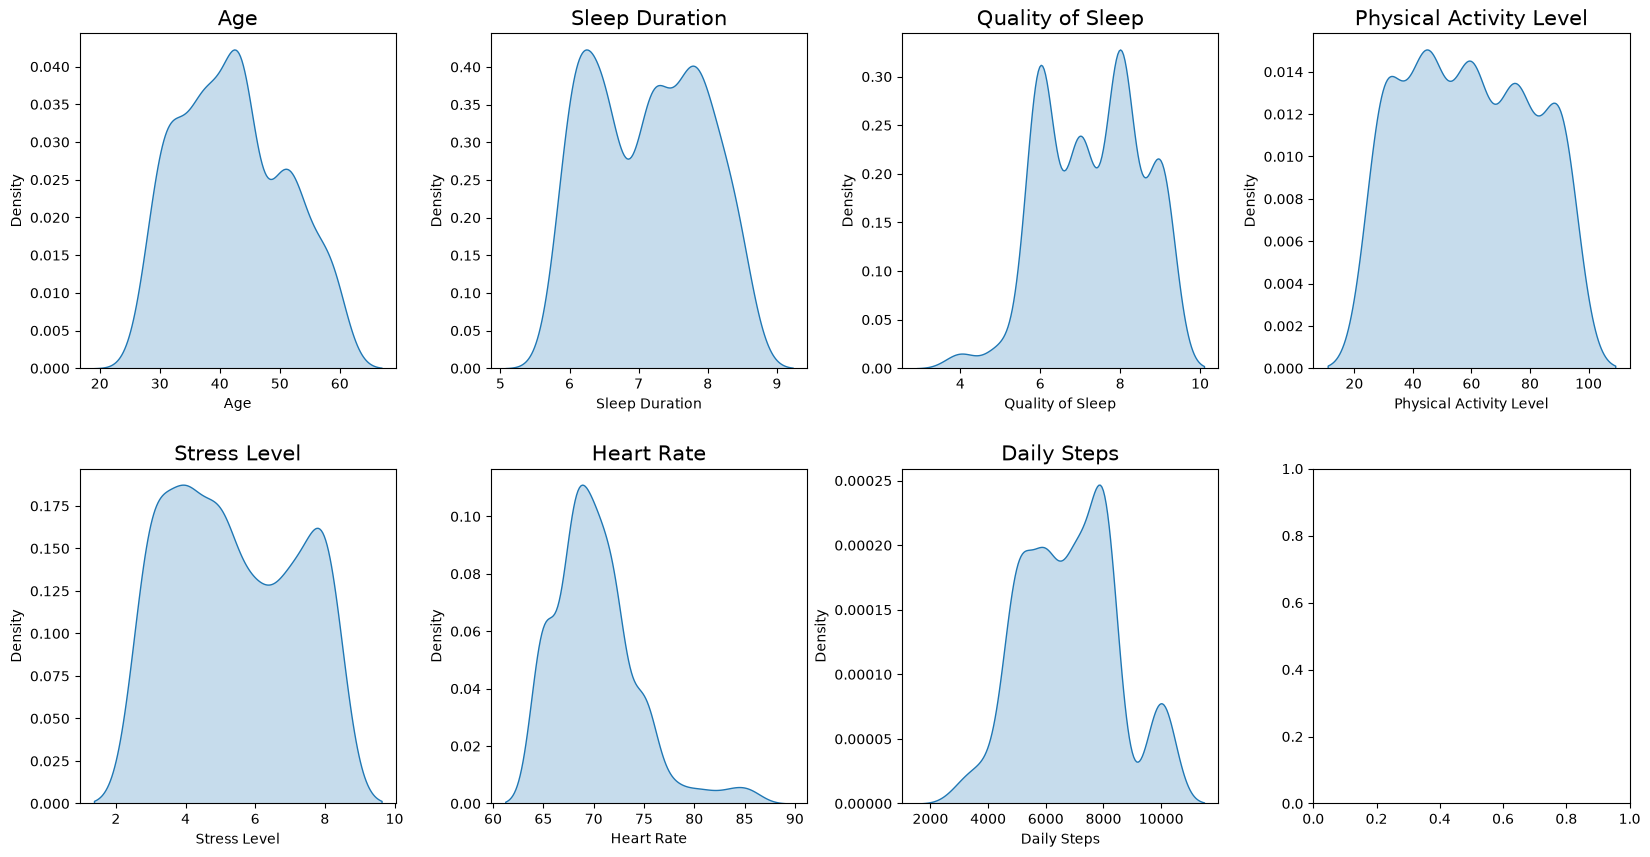

In [13]:
import warnings
warnings.filterwarnings("ignore")

cols = ['Age', 'Sleep Duration', 'Quality of Sleep',
        'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']

# plot data distribution
fig, axs = plt.subplots(2, 4, figsize=(20, 10))
axs = axs.flatten()
#sns.set_style('white')
#sns.set_palette("PuRd")

for i, var in enumerate(cols):
    sns.kdeplot(x=var, ax=axs[i], fill=True, data=sleep_df)
    axs[i].set_title(var, fontsize=15)

plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.show()

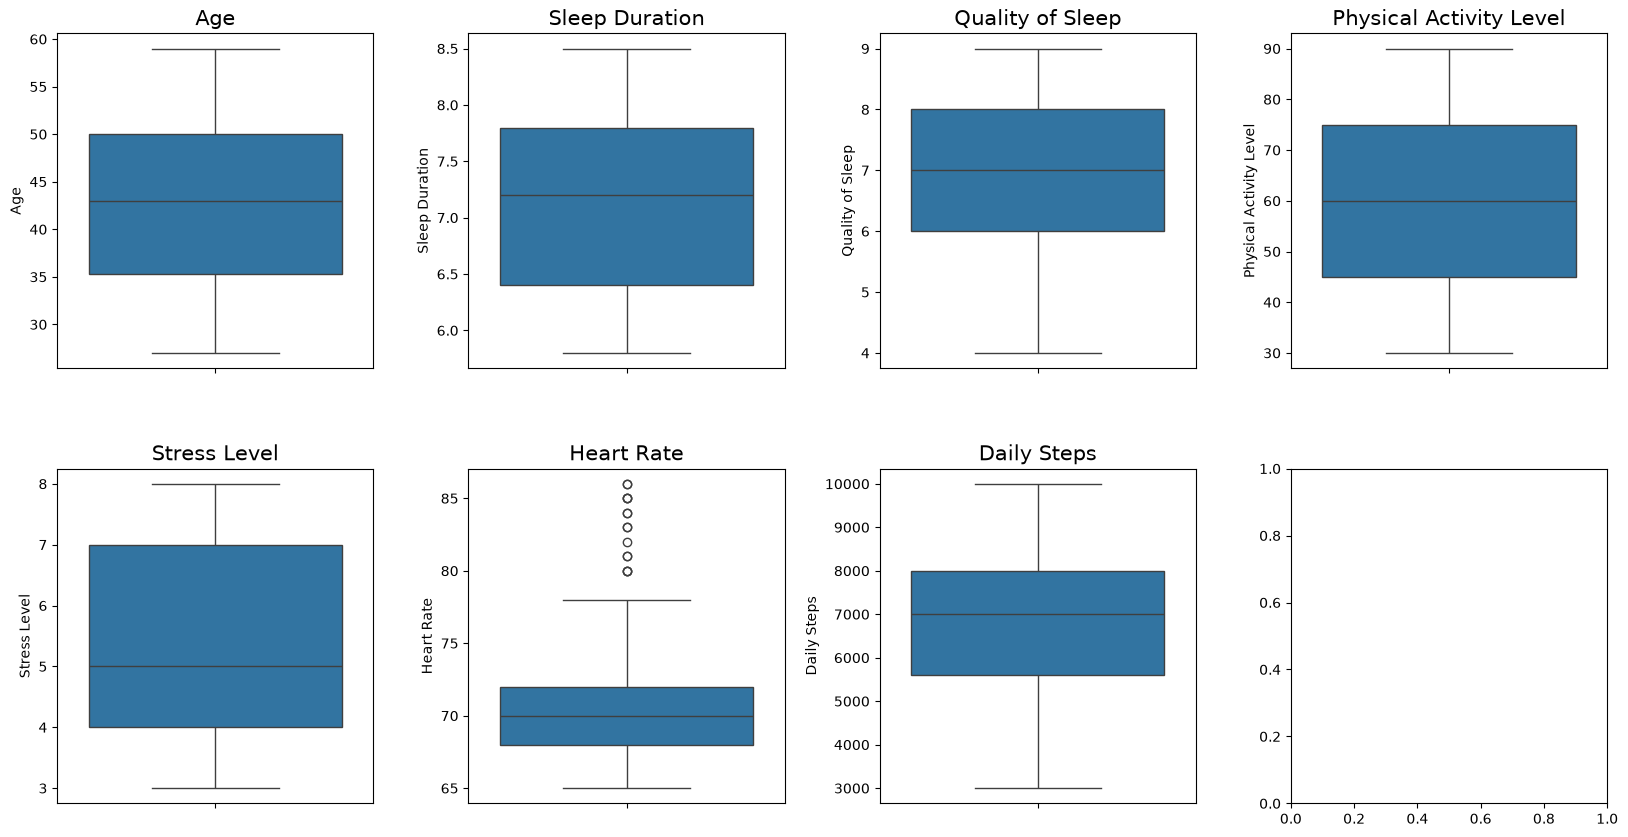

In [14]:
# plot data distribution
fig, axs = plt.subplots(2, 4, figsize=(20, 10))
axs = axs.flatten()
#sns.set_style('white')
#sns.set_palette("PuRd")

for i, var in enumerate(cols):
    sns.boxplot(y=var, ax=axs[i], fill=True, data=sleep_df)
    axs[i].set_title(var, fontsize=15)

plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.show()

In [15]:
#inspecting outliers

Q1 = sleep_df['Heart Rate'].quantile(0.25)
Q3 = sleep_df['Heart Rate'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

outliers = sleep_df['Heart Rate'][(sleep_df['Heart Rate'] < lower_bound) | (sleep_df['Heart Rate'] > upper_bound)]

print(f'Total number of outlier is {outliers.count().sum()}')

Total number of outlier is 15


In [16]:
cat = sleep_df.select_dtypes(exclude=['int64','float64'])
cat.drop('Blood Pressure', axis=1, inplace=True)
cat

,Gender,Occupation,BMI Category,Sleep Disorder,Age_cat
0,Male,Software Engineer,Overweight,No disorder,young_adult
1,Male,Doctor,Normal,No disorder,young_adult
2,Male,Doctor,Normal,No disorder,young_adult
3,Male,Sales Representative,Obese,Sleep Apnea,young_adult
4,Male,Sales Representative,Obese,Sleep Apnea,young_adult
...,...,...,...,...,...
369,Female,Nurse,Overweight,Sleep Apnea,elderlies
370,Female,Nurse,Overweight,Sleep Apnea,elderlies
371,Female,Nurse,Overweight,Sleep Apnea,elderlies
372,Female,Nurse,Overweight,Sleep Apnea,elderlies


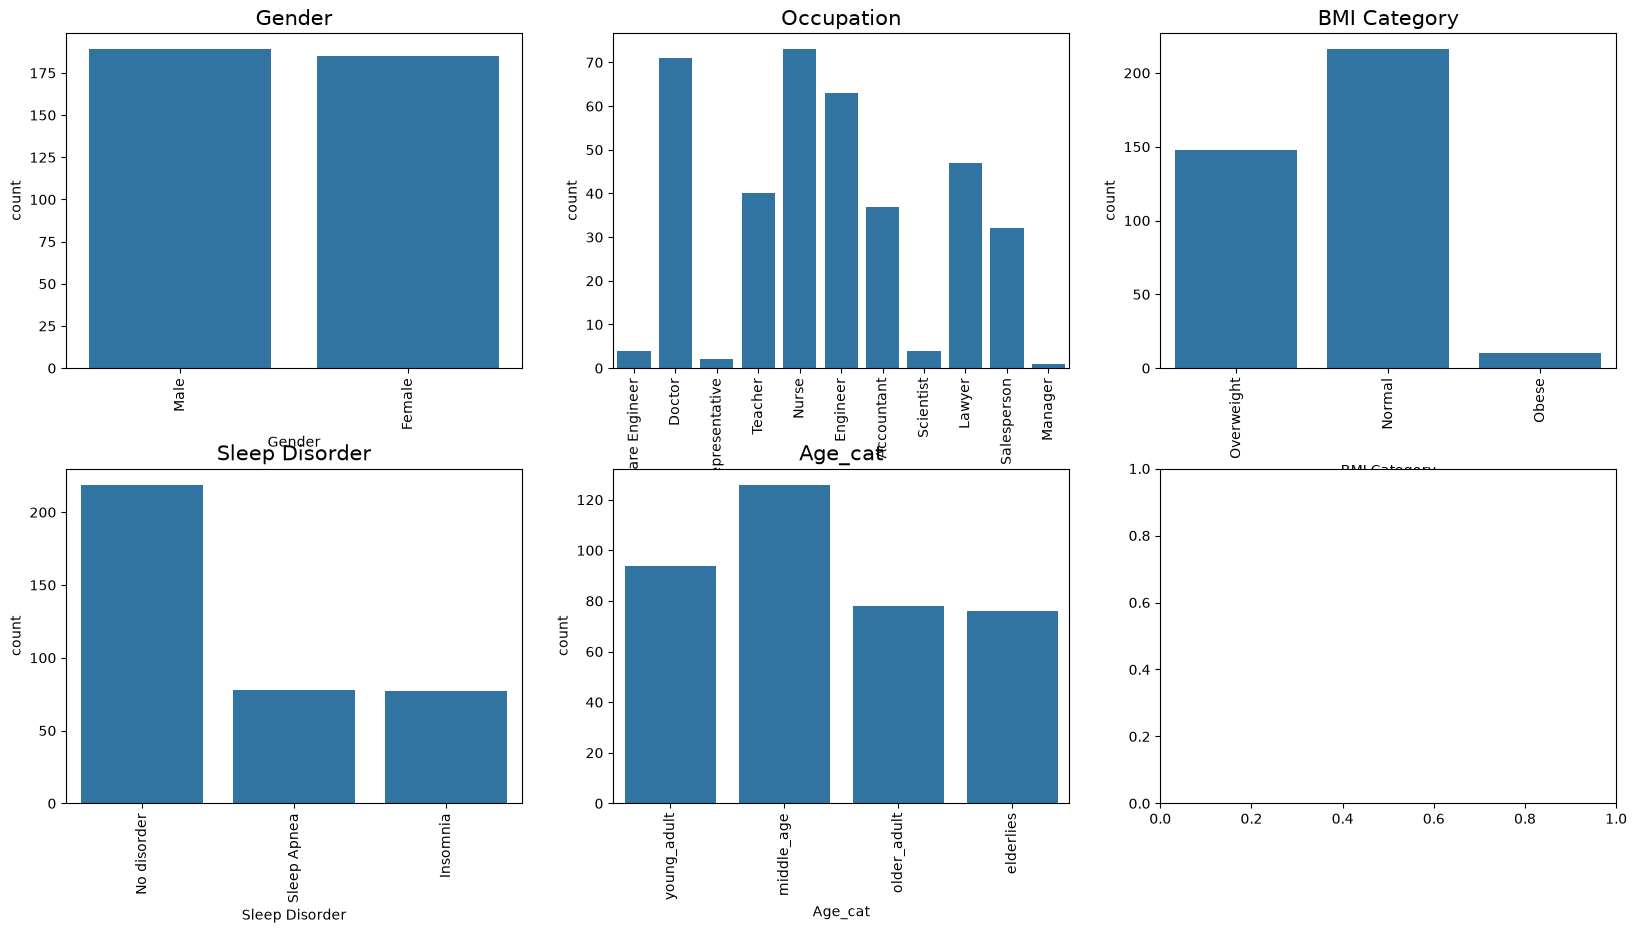

In [17]:
# plot data distribution
fig, axs = plt.subplots(2, 3, figsize=(20, 10))
axs = axs.flatten()
#sns.set_style('white')
#sns.set_palette("PuRd")

for i, var in enumerate(cat.columns):
    sns.countplot(x=var, ax=axs[i], data=cat)
    axs[i].set_title(var, fontsize=15)
    axs[i].tick_params(axis='x', labelrotation=90)

plt.subplots_adjust(hspace=0.3, wspace=0.2)
plt.show()

In [18]:
#using groupby to get sleep duration summary statistics
sleep_df.groupby('Occupation')['Sleep Duration'].describe()

,count,mean,std,min,25%,50%,75%,max
Occupation,,,,,,,,
Accountant,37.0,7.113514,0.312838,6.5,7.10,7.2,7.200,8.0
Doctor,71.0,6.970423,0.863613,6.0,6.05,7.6,7.700,8.2
Engineer,63.0,7.987302,0.511005,6.5,7.70,8.3,8.400,8.5
Lawyer,47.0,7.410638,0.270454,6.9,7.20,7.3,7.700,7.9
Manager,1.0,6.900000,NaN,6.9,6.90,6.9,6.900,6.9
Nurse,73.0,7.063014,0.990301,5.9,6.10,6.5,8.100,8.2
Sales Representative,2.0,5.900000,0.000000,5.9,5.90,5.9,5.900,5.9
Salesperson,32.0,6.403125,0.089747,6.3,6.30,6.4,6.500,6.5
Scientist,4.0,6.000000,0.230940,5.8,5.80,6.0,6.200,6.2


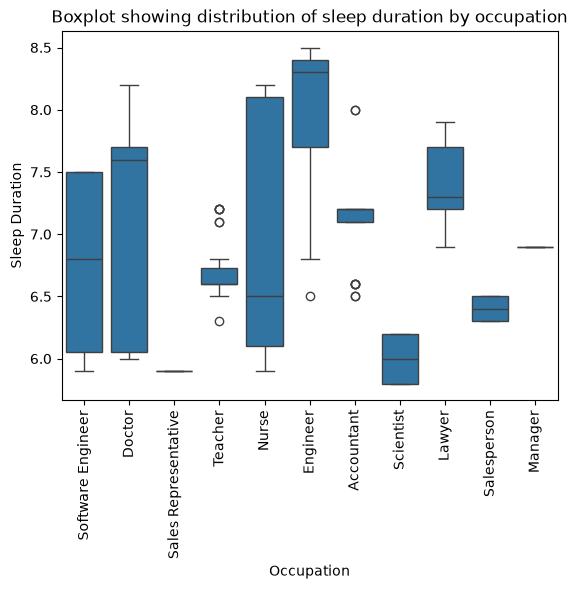

In [19]:
#distribution of sleep duration by occupation
sns.boxplot(x='Occupation', y='Sleep Duration', data=sleep_df)
plt.xticks(rotation=90)
plt.title("Boxplot showing distribution of sleep duration by occupation")
plt.show()

In [20]:
#using groupy to get sleep quality summary statistics
sleep_df.groupby('Occupation')['Quality of Sleep'].describe()

,count,mean,std,min,25%,50%,75%,max
Occupation,,,,,,,,
Accountant,37.0,7.891892,0.458487,7.0,8.0,8.0,8.0,9.0
Doctor,71.0,6.647887,0.757790,6.0,6.0,7.0,7.0,9.0
Engineer,63.0,8.412698,0.754234,5.0,8.0,9.0,9.0,9.0
Lawyer,47.0,7.893617,0.311661,7.0,8.0,8.0,8.0,8.0
Manager,1.0,7.000000,NaN,7.0,7.0,7.0,7.0,7.0
Nurse,73.0,7.369863,1.550151,5.0,6.0,6.0,9.0,9.0
Sales Representative,2.0,4.000000,0.000000,4.0,4.0,4.0,4.0,4.0
Salesperson,32.0,6.000000,0.000000,6.0,6.0,6.0,6.0,6.0
Scientist,4.0,5.000000,1.154701,4.0,4.0,5.0,6.0,6.0


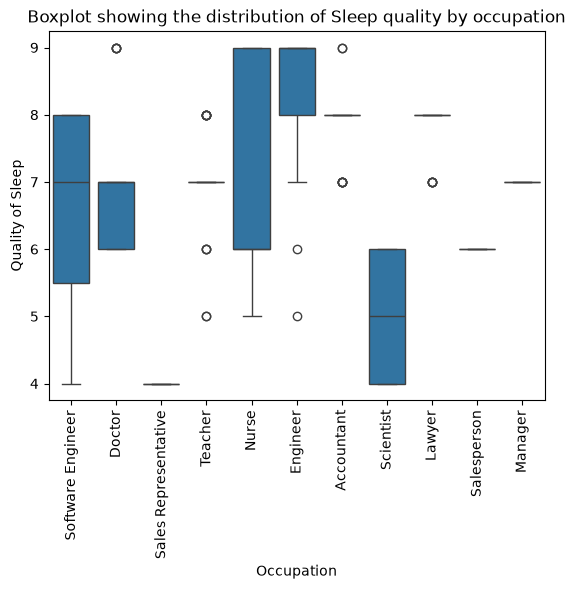

In [21]:
#distribution of Quality of Sleep by occupation
sns.boxplot(x='Occupation', y='Quality of Sleep', data=sleep_df)
plt.xticks(rotation=90)
plt.title("Boxplot showing the distribution of Sleep quality by occupation")
plt.show()

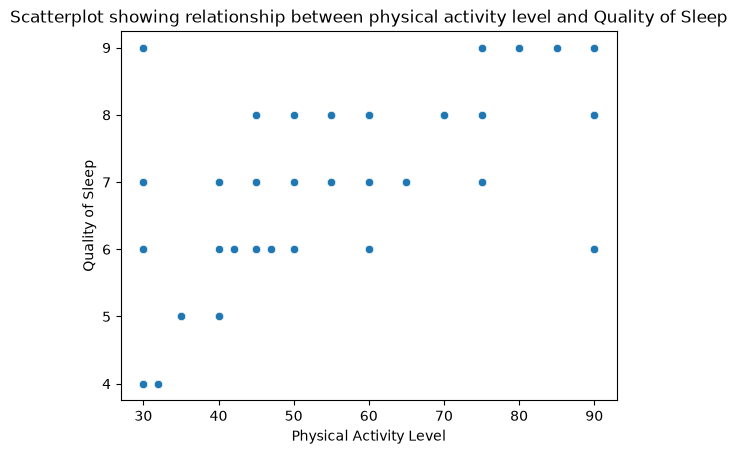

In [22]:
#Does an increased physical activity level result in a better quality of sleep?
sns.scatterplot(x='Physical Activity Level', y='Quality of Sleep', data=sleep_df)
plt.title("Scatterplot showing relationship between physical activity level and Quality of Sleep")
plt.show()

In [23]:
df = sleep_df[['Quality of Sleep', 'Physical Activity Level']]

print(df['Physical Activity Level'].unique())

print ("-------------------------------------")

print(df['Physical Activity Level'].describe())

group_A = df[df["Physical Activity Level"] >= 60]

group_B = df[~(df["Physical Activity Level"] >= 60)]

[42 60 30 40 75 35 45 50 32 70 80 55 90 47 65 85]
-------------------------------------
count    374.000000
mean      59.171123
std       20.830804
min       30.000000
25%       45.000000
50%       60.000000
75%       75.000000
max       90.000000
Name: Physical Activity Level, dtype: float64


In [24]:
import scipy.stats as stats

# Sample data
group_A_sleep_quality = group_A['Quality of Sleep']
group_B_sleep_quality = group_B['Quality of Sleep']

# Perform an independent t-test
t_stat, p_value = stats.ttest_ind(group_A_sleep_quality, group_B_sleep_quality) 

# Check if the p-value is less than the significance level (e.g., 0.05)
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference in sleep quality.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference in sleep quality.")


Reject the null hypothesis: There is a significant difference in sleep quality.


In [25]:
sleep_df.groupby('Sleep Disorder')['Quality of Sleep'].describe()

,count,mean,std,min,25%,50%,75%,max
Sleep Disorder,,,,,,,,
Insomnia,77.0,6.532468,0.804337,4.0,6.0,7.0,7.0,9.0
No disorder,219.0,7.625571,0.975142,6.0,7.0,8.0,8.0,9.0
Sleep Apnea,78.0,7.205128,1.646397,4.0,6.0,6.0,9.0,9.0


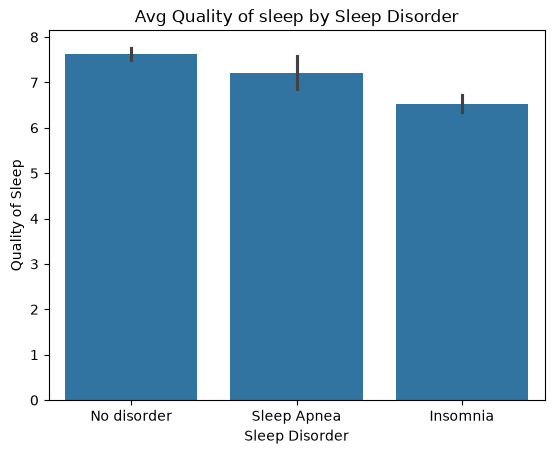

In [26]:
sns.barplot(x='Sleep Disorder', y='Quality of Sleep', data=sleep_df)
plt.title("Avg Quality of sleep by Sleep Disorder")
sns.set_palette('Blues')
plt.show()

In [27]:
%pip install pingouin

Note: you may need to restart the kernel to use updated packages.


In [28]:
#Does the presence of a sleep disorder affect the subjective sleep quality metric?
# Import the required library
import pingouin

# Perform the ANOVA test
anova_df = pingouin.anova(data=sleep_df, dv='Quality of Sleep', between='Sleep Disorder')

# Extract the p-value from the ANOVA results
p_value = anova_df.loc[0, 'p_unc']

# Check if the p-value is less than your chosen significance level (e.g., 0.05)
if p_value < 0.05:
    print("There is a statistically significant difference in subjective sleep quality among the groups.")
else:
    print("There is no statistically significant difference in subjective sleep quality among the groups.")

There is a statistically significant difference in subjective sleep quality among the groups.


In [29]:
sleep_df.groupby('Age_cat')['Sleep Duration'].describe()

,count,mean,std,min,25%,50%,75%,max
Age_cat,,,,,,,,
young_adult,94.0,6.854255,0.788174,5.8,6.1,6.7,7.7,7.9
middle_age,126.0,7.243651,0.435154,6.1,7.1,7.2,7.7,8.0
older_adult,78.0,6.421795,0.454029,5.9,6.1,6.3,6.6,8.3
elderlies,76.0,8.019737,0.640421,6.0,8.0,8.2,8.4,8.5


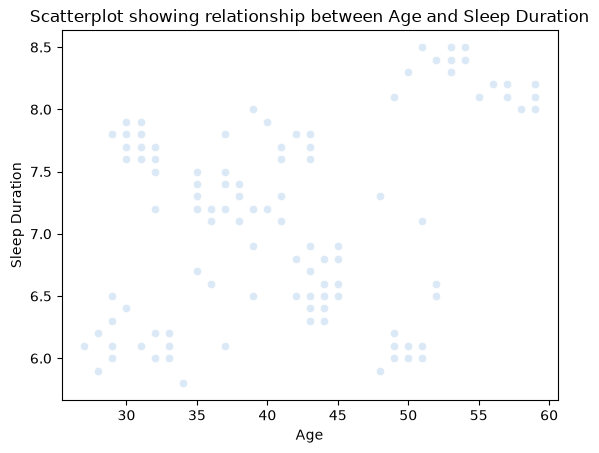

In [30]:
sns.scatterplot(x='Age', y='Sleep Duration', data=sleep_df)
plt.title("Scatterplot showing relationship between Age and Sleep Duration")
plt.show()

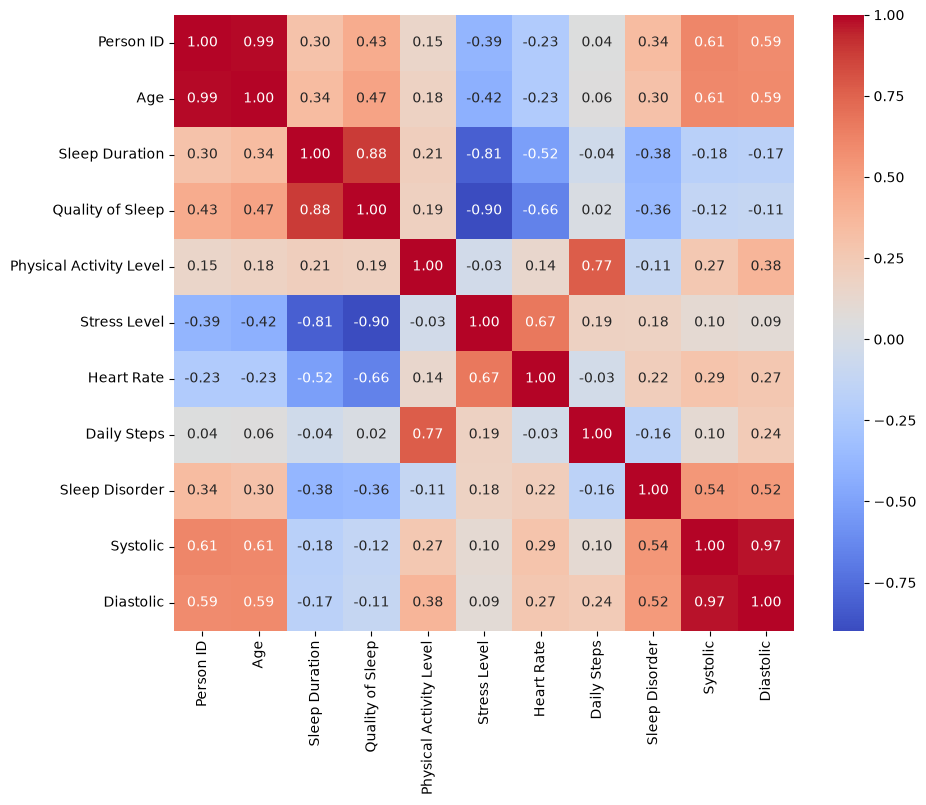

In [31]:
#encode Sleep Disorder as numbers for the correlation heatmap only
numeric_df = sleep_df.copy()
numeric_df['Sleep Disorder'] = numeric_df['Sleep Disorder'].map({'No disorder': 0, 'Sleep Apnea': 1, 'Insomnia': 2})
numeric_df = numeric_df.select_dtypes(include=['number'])

numeric_corr_matrix = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

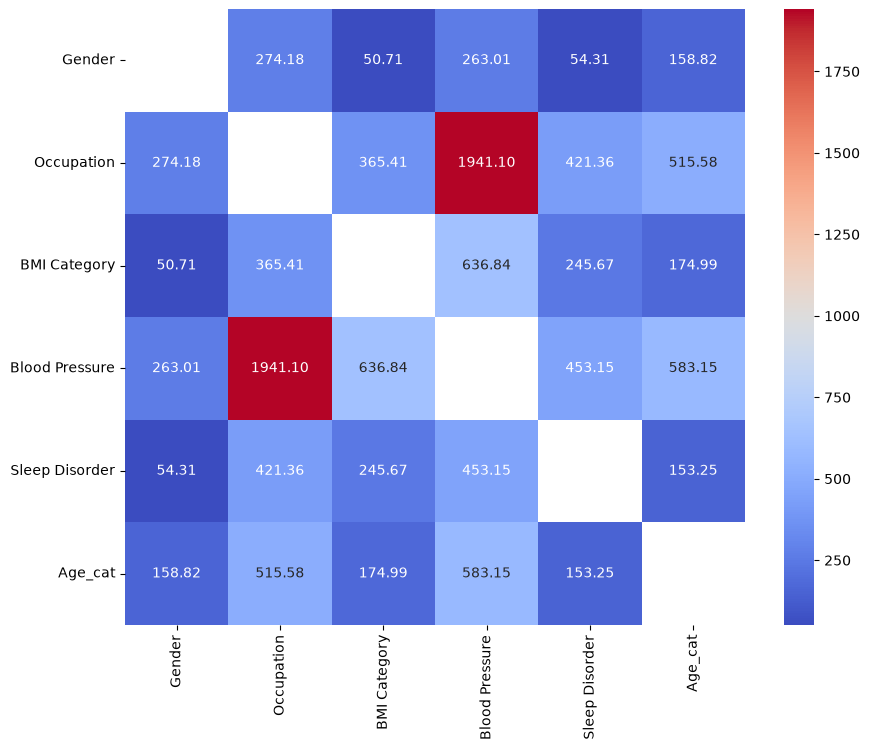

In [32]:
from scipy.stats import chi2_contingency
categorical_df = sleep_df.select_dtypes(exclude=['number'])
# Assuming 'categorical_df' contains only categorical variables
chi2_matrix = pd.DataFrame(index=categorical_df.columns, columns=categorical_df.columns)

for col1 in categorical_df.columns:
    for col2 in categorical_df.columns:
        if col1 != col2:
            contingency_table = pd.crosstab(categorical_df[col1], categorical_df[col2])
            chi2, _, _, _ = chi2_contingency(contingency_table)
            chi2_matrix.loc[col1, col2] = chi2

# Visualize the chi-squared matrix
plt.figure(figsize=(10, 8))
sns.heatmap(chi2_matrix.astype(float), annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [33]:
#ranking sleep disorder by age group
age_group = sleep_df.groupby(['Age_cat', 'Sleep Disorder']).size().reset_index(name='counts')
#age_group

pivot_table = pd.pivot_table(age_group, index='Sleep Disorder',
                             columns='Age_cat',
                             values='counts').rank(ascending=False, axis=0)
pivot_table

Age_cat,young_adult,middle_age,older_adult,elderlies
Sleep Disorder,,,,
Insomnia,3.0,2.0,1.0,3.0
No disorder,1.0,1.0,3.0,1.0
Sleep Apnea,2.0,3.0,2.0,2.0


In [34]:
sleep_df['Sleep Disorder'].value_counts(dropna=False)

Sleep Disorder
No disorder    219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [35]:
def color_rank_one(val):
    '''This function applies the mediumturquoise background color to the first rank'''
    if val == 1:
        return "background-color: mediumturquoise"
    else:
        return ''

pivot_table.style.format('{:,.0f}').background_gradient(cmap='Blues_r', axis=0).map(color_rank_one)

Age_cat,young_adult,middle_age,older_adult,elderlies
Sleep Disorder,,,,
Insomnia,3,2,1,3
No disorder,1,1,3,1
Sleep Apnea,2,3,2,2


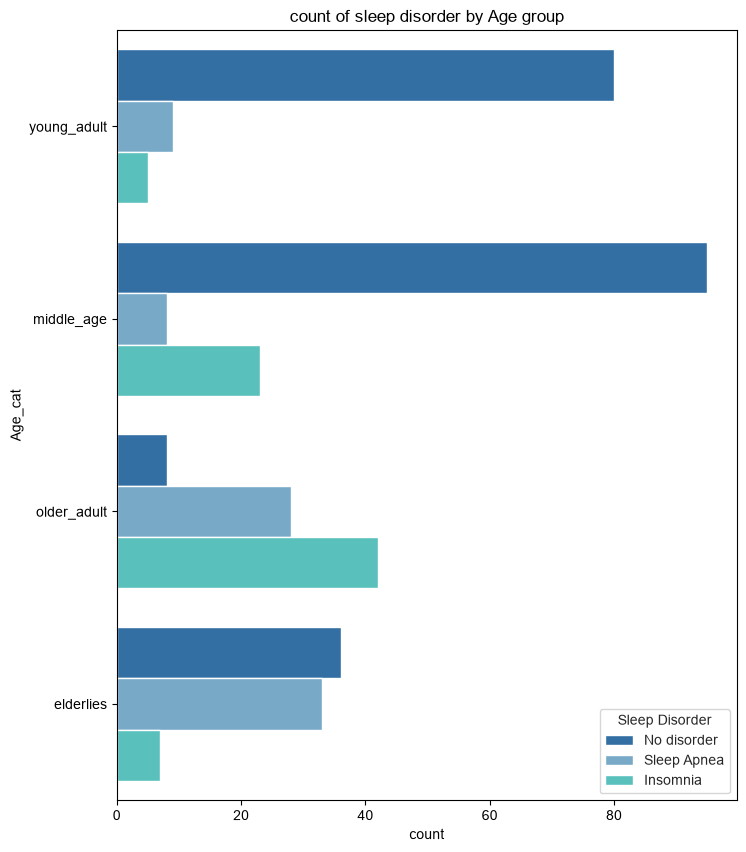

In [36]:
#plot sleep disorder by age group
fig,ax = plt.subplots(figsize=(8,10))
sns.set_style('white')

sleep_disorder = sleep_df[sleep_df['Sleep Disorder'] != 'Missing']
unique_sleepdisorder = sleep_disorder["Sleep Disorder"].unique()

blues = sns.color_palette("Blues", n_colors=len(unique_sleepdisorder))
custom_palette = ['mediumturquoise' if diag == "Insomnia"
                  else blues[len(unique_sleepdisorder) - 1 - i]
                  for i, diag in enumerate(unique_sleepdisorder)]

sns.countplot(y='Age_cat',
              hue='Sleep Disorder', order=sleep_disorder.Age_cat.sort_values().unique(),
              data = sleep_disorder,
              palette = custom_palette)
plt.title("count of sleep disorder by Age group")
plt.savefig('sleep_disorder_by_age.png', dpi=150, bbox_inches='tight')
plt.show()

In [37]:
#Table Sleep disorder vs gender
table_1 = (sleep_df.groupby('Gender')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

#Table Sleep disorder vs Occupation
table_2 = (sleep_df.groupby('Occupation')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

#Table Sleep disorder vs BMI Category
table_3 = (sleep_df.groupby('BMI Category')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

#Table Sleep disorder vs Blood Pressure
table_4 = (sleep_df.groupby('Blood Pressure')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

#Table Sleep disorder vs Daily Steps
table_5 = (sleep_df.groupby('Daily Steps')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

#Table Sleep disorder vs Physical Activity level
table_6 = (sleep_df.groupby('Physical Activity Level')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

#Table Sleep disorder vs Heart Rate
table_7 = (sleep_df.groupby('Heart Rate')['Sleep Disorder']
           .value_counts(normalize=True)
           .mul(100)
           .round()
           .reset_index(name='Sleep disorder rate (%)'))

In [38]:
table_1

,Gender,Sleep Disorder,Sleep disorder rate (%)
0,Female,No disorder,44.0
1,Female,Sleep Apnea,36.0
2,Female,Insomnia,19.0
3,Male,No disorder,72.0
4,Male,Insomnia,22.0
5,Male,Sleep Apnea,6.0


In [39]:
table_2

,Occupation,Sleep Disorder,Sleep disorder rate (%)
0,Accountant,No disorder,81.0
1,Accountant,Insomnia,19.0
2,Doctor,No disorder,90.0
3,Doctor,Sleep Apnea,6.0
4,Doctor,Insomnia,4.0
5,Engineer,No disorder,90.0
6,Engineer,Insomnia,8.0
7,Engineer,Sleep Apnea,2.0
8,Lawyer,No disorder,89.0
9,Lawyer,Sleep Apnea,6.0


In [40]:
table_3

,BMI Category,Sleep Disorder,Sleep disorder rate (%)
0,Normal,No disorder,93.0
1,Normal,Insomnia,4.0
2,Normal,Sleep Apnea,3.0
3,Obese,Sleep Apnea,60.0
4,Obese,Insomnia,40.0
5,Overweight,Sleep Apnea,44.0
6,Overweight,Insomnia,43.0
7,Overweight,No disorder,13.0


In [41]:
table_4

,Blood Pressure,Sleep Disorder,Sleep disorder rate (%)
0,115/75,No disorder,94.0
1,115/75,Insomnia,3.0
2,115/75,Sleep Apnea,3.0
3,115/78,No disorder,100.0
4,117/76,No disorder,100.0
5,118/75,No disorder,100.0
6,118/76,No disorder,100.0
7,119/77,No disorder,100.0
8,120/80,No disorder,96.0
9,120/80,Sleep Apnea,4.0


In [42]:
table_5

,Daily Steps,Sleep Disorder,Sleep disorder rate (%)
0,3000,Sleep Apnea,67.0
1,3000,Insomnia,33.0
2,3300,Sleep Apnea,100.0
3,3500,Insomnia,100.0
4,3700,Sleep Apnea,100.0
5,4000,Insomnia,67.0
6,4000,Sleep Apnea,33.0
7,4100,Insomnia,50.0
8,4100,Sleep Apnea,50.0
9,4200,No disorder,100.0


In [43]:
table_6

,Physical Activity Level,Sleep Disorder,Sleep disorder rate (%)
0,30,No disorder,88.0
1,30,Insomnia,7.0
2,30,Sleep Apnea,4.0
3,32,Sleep Apnea,100.0
4,35,Insomnia,50.0
5,35,Sleep Apnea,50.0
6,40,Insomnia,50.0
7,40,No disorder,33.0
8,40,Sleep Apnea,17.0
9,42,No disorder,100.0


In [44]:
table_7

,Heart Rate,Sleep Disorder,Sleep disorder rate (%)
0,65,No disorder,61.0
1,65,Insomnia,39.0
2,67,No disorder,100.0
3,68,No disorder,66.0
4,68,Sleep Apnea,32.0
5,68,Insomnia,2.0
6,69,No disorder,100.0
7,70,No disorder,92.0
8,70,Insomnia,4.0
9,70,Sleep Apnea,4.0


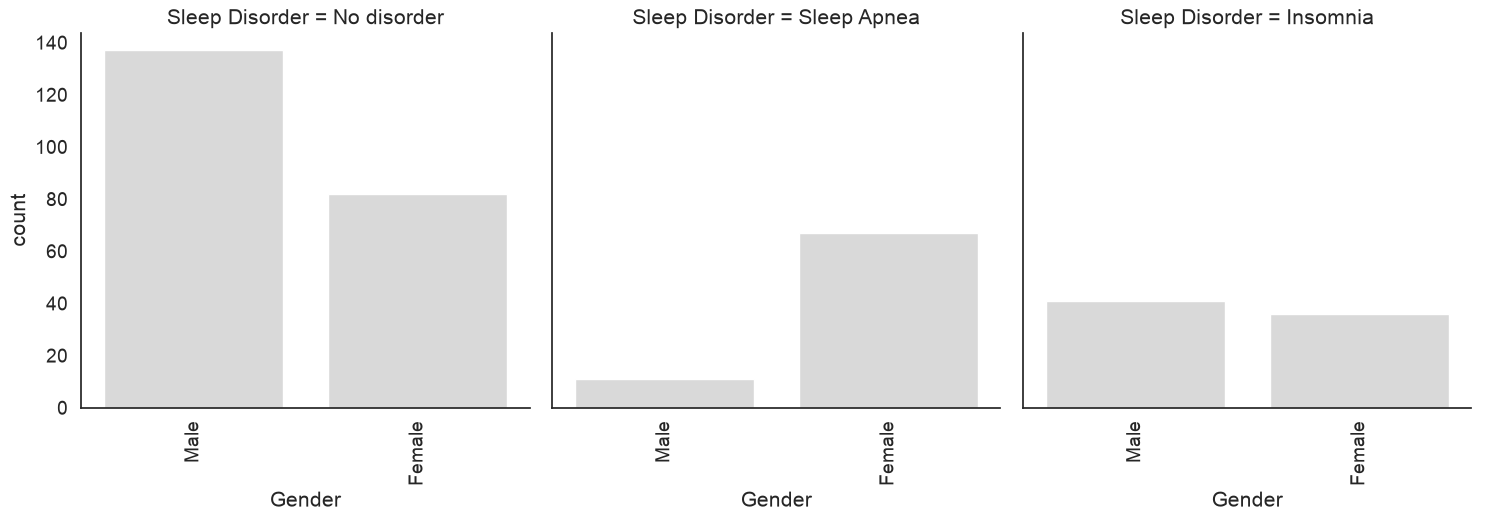

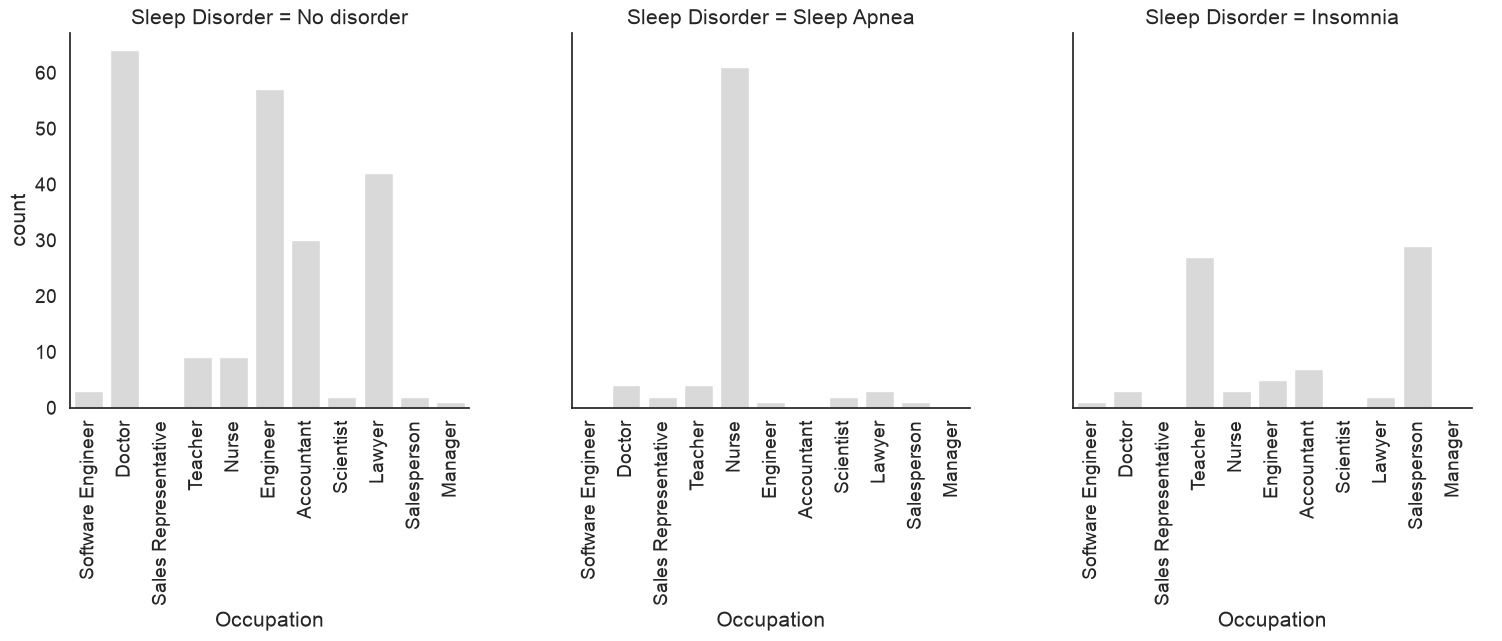

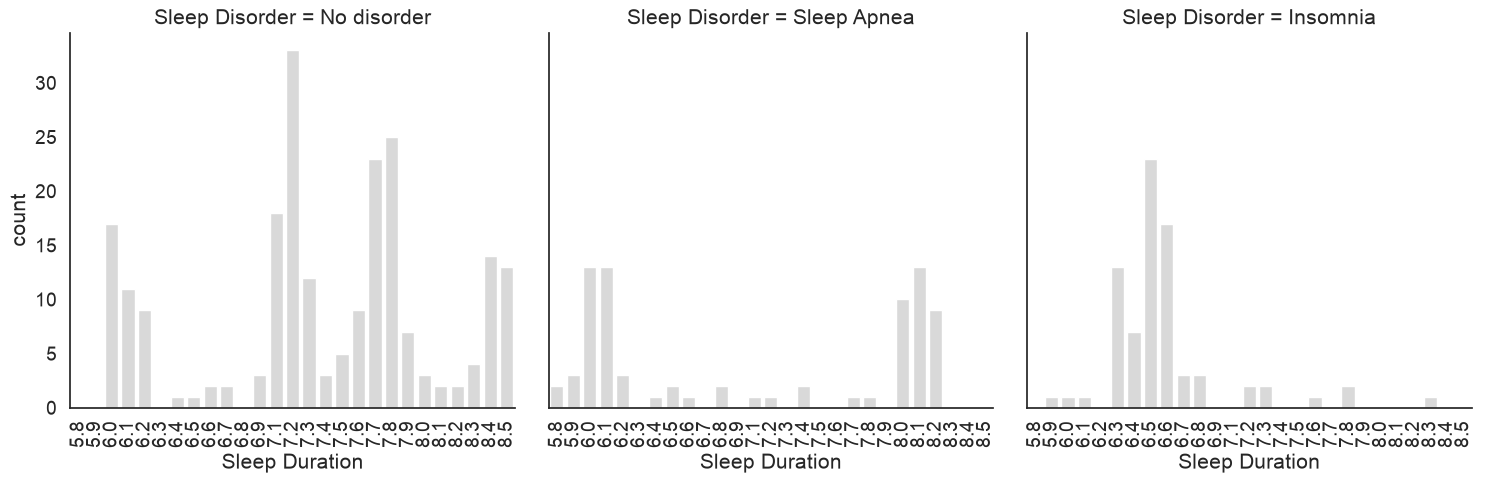

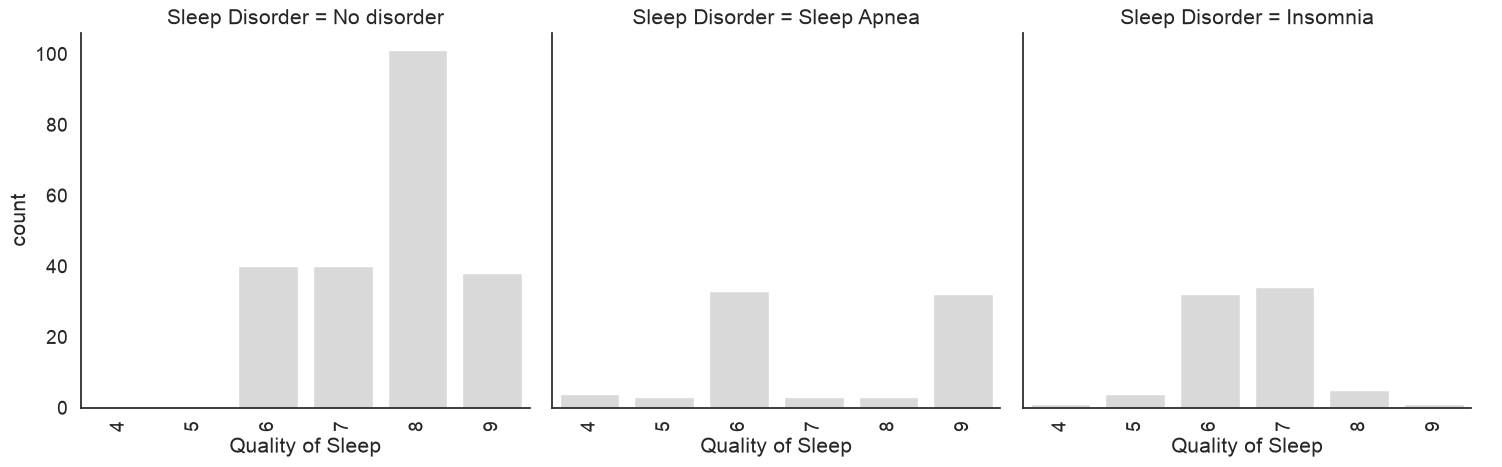

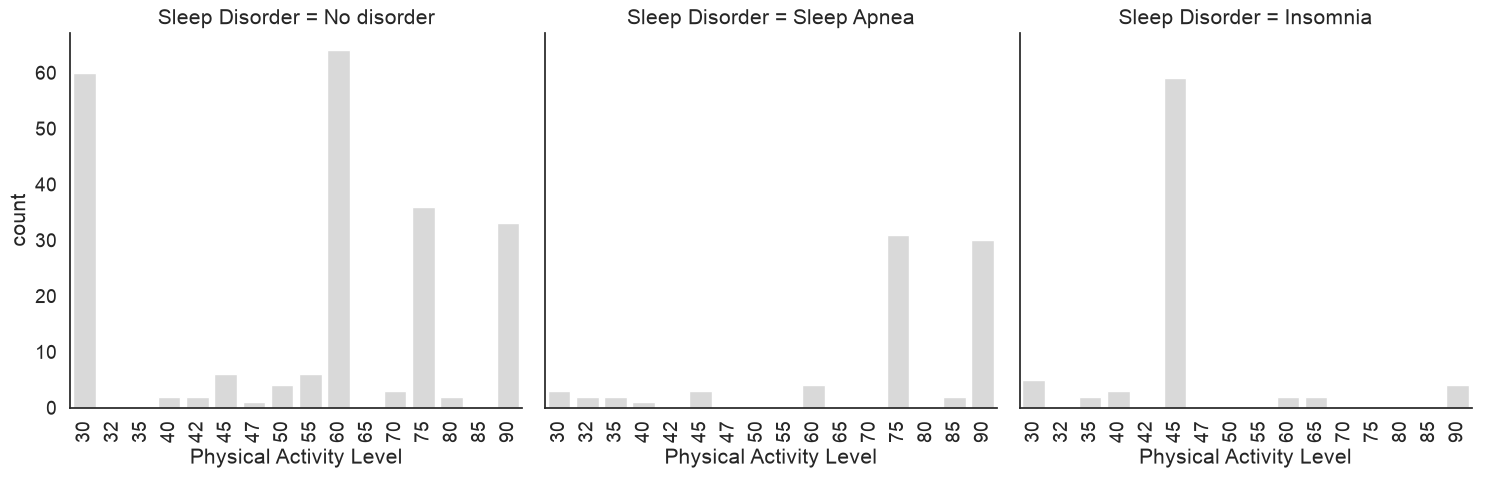

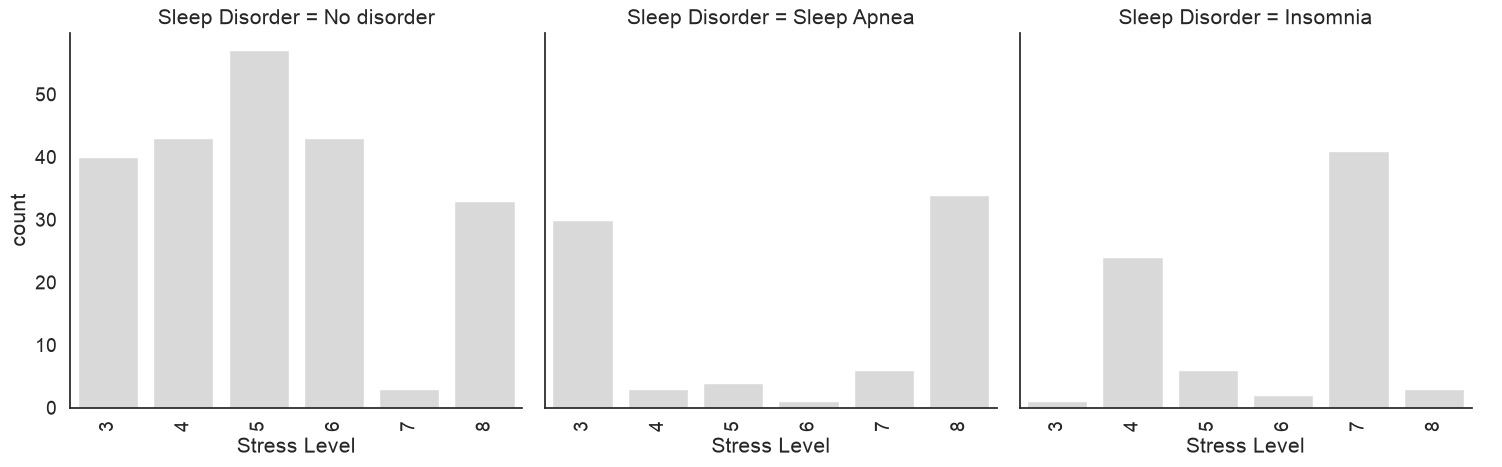

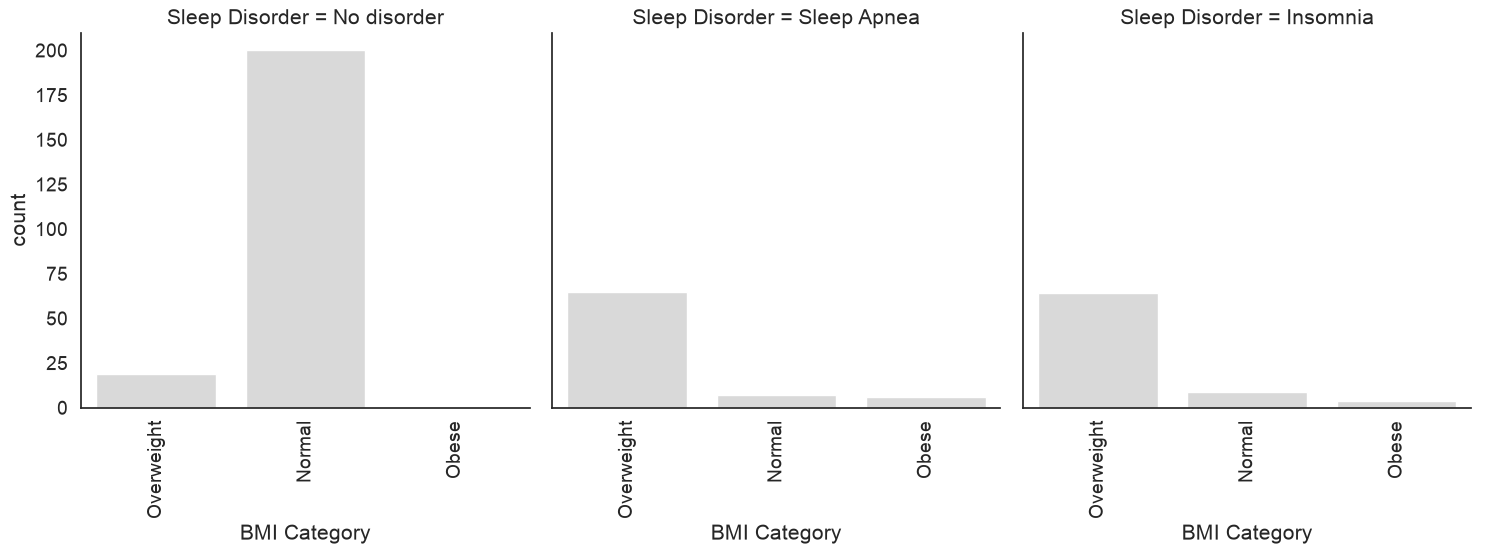

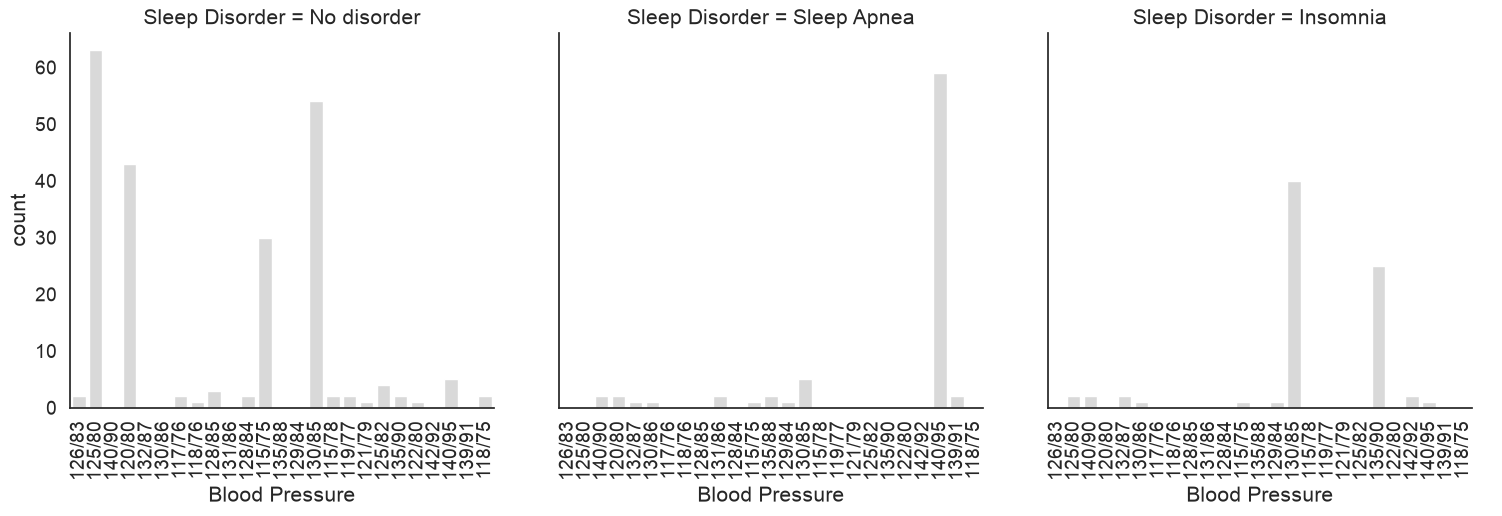

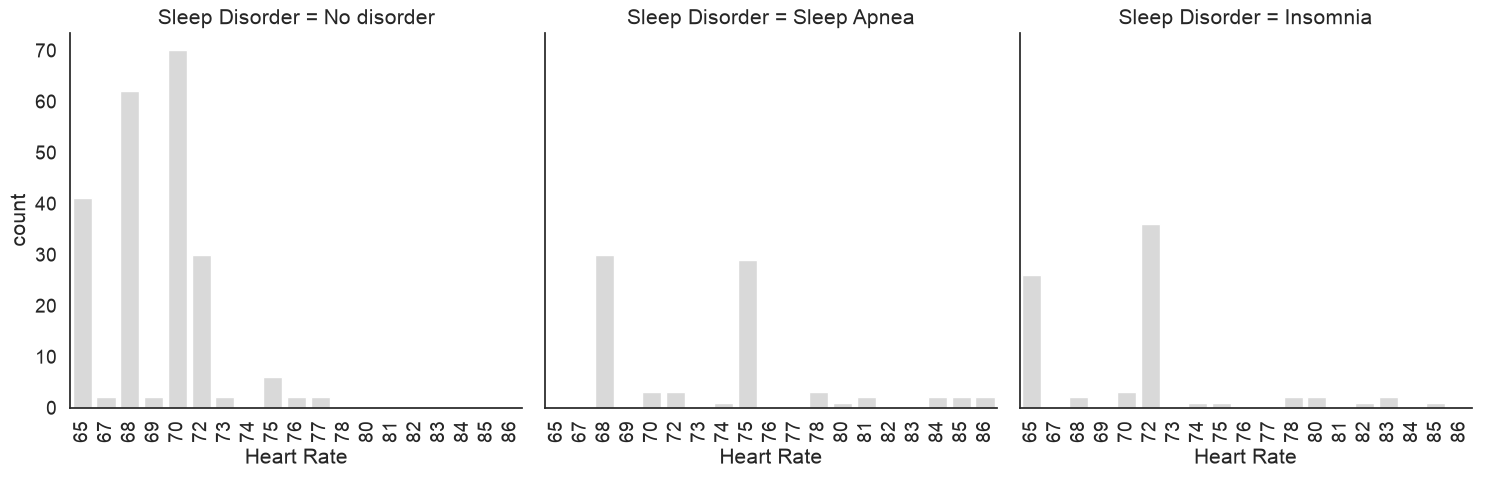

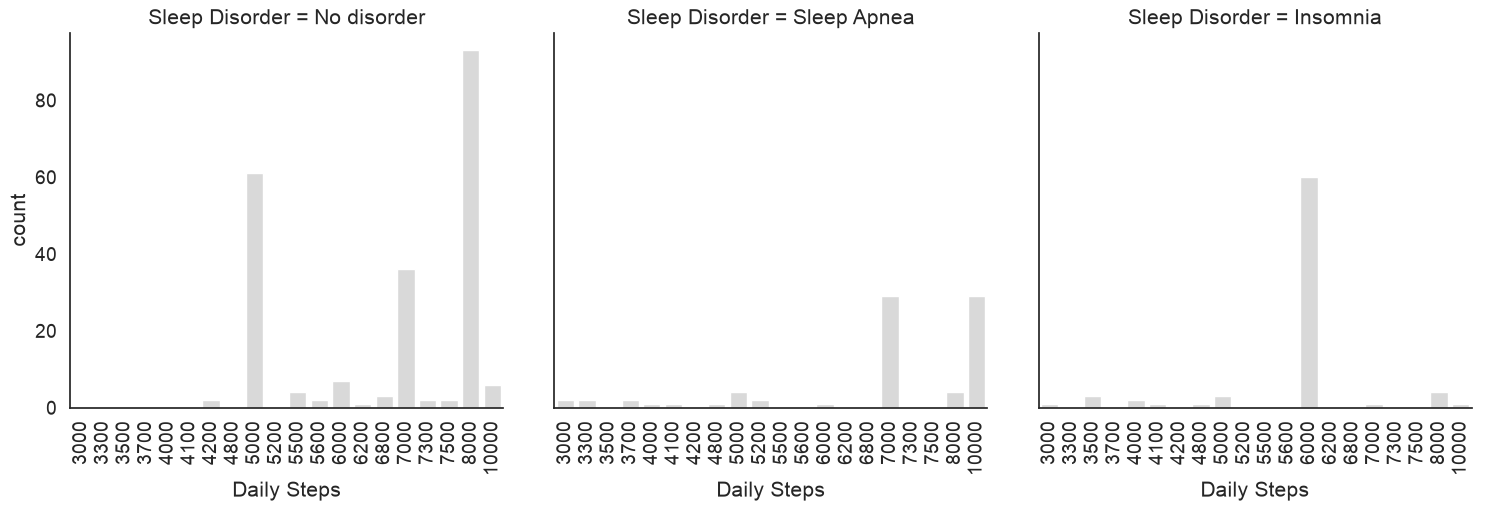

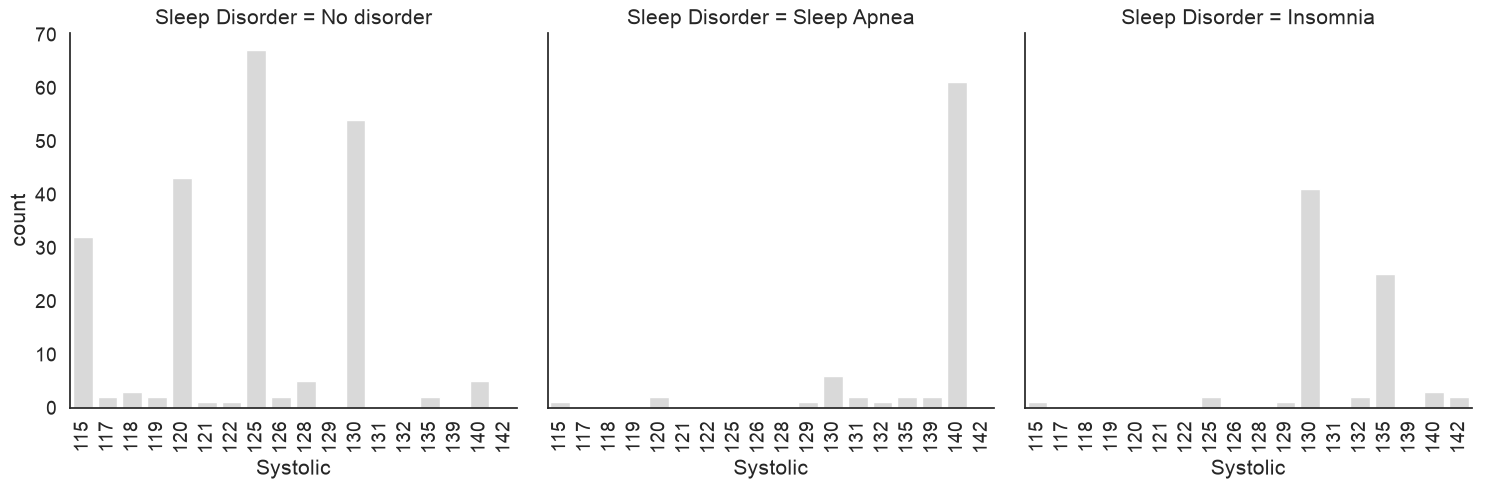

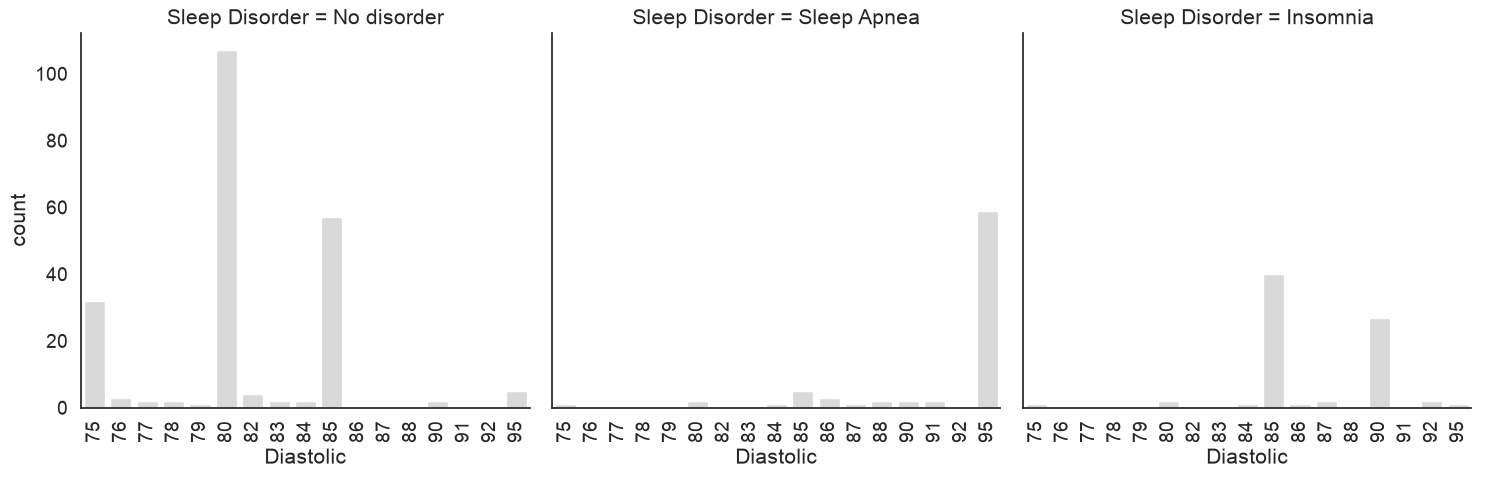

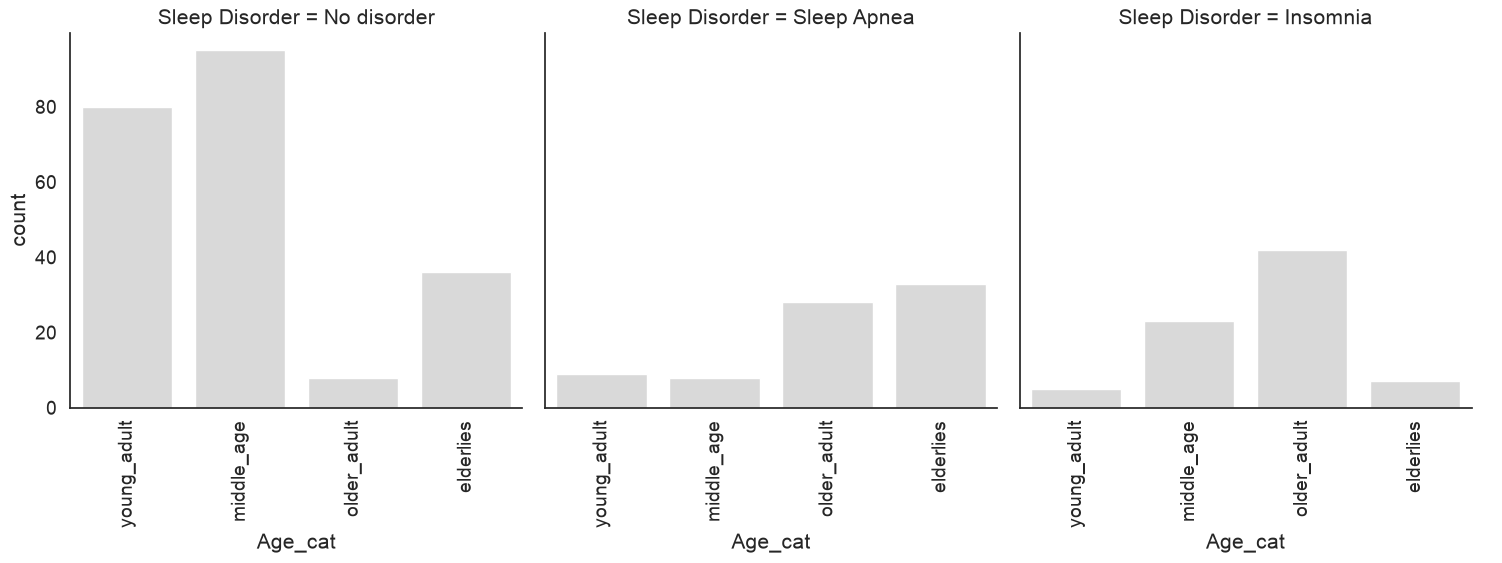

In [45]:
cols = sleep_df.columns
cols = [col for col in cols if col not in ['Person ID', 'Sleep Disorder', 'Age']]

sns.set(style='white',font_scale=1.25)
sns.set_palette('Greys',3)

def plot_bar_graph():
    for c in cols:
        g = sns.catplot(x=c, col='Sleep Disorder', data=sleep_df, kind='count')
        g.set_xticklabels(rotation=90)
        #plt.title(c)
        plt.show()

plot_bar_graph()

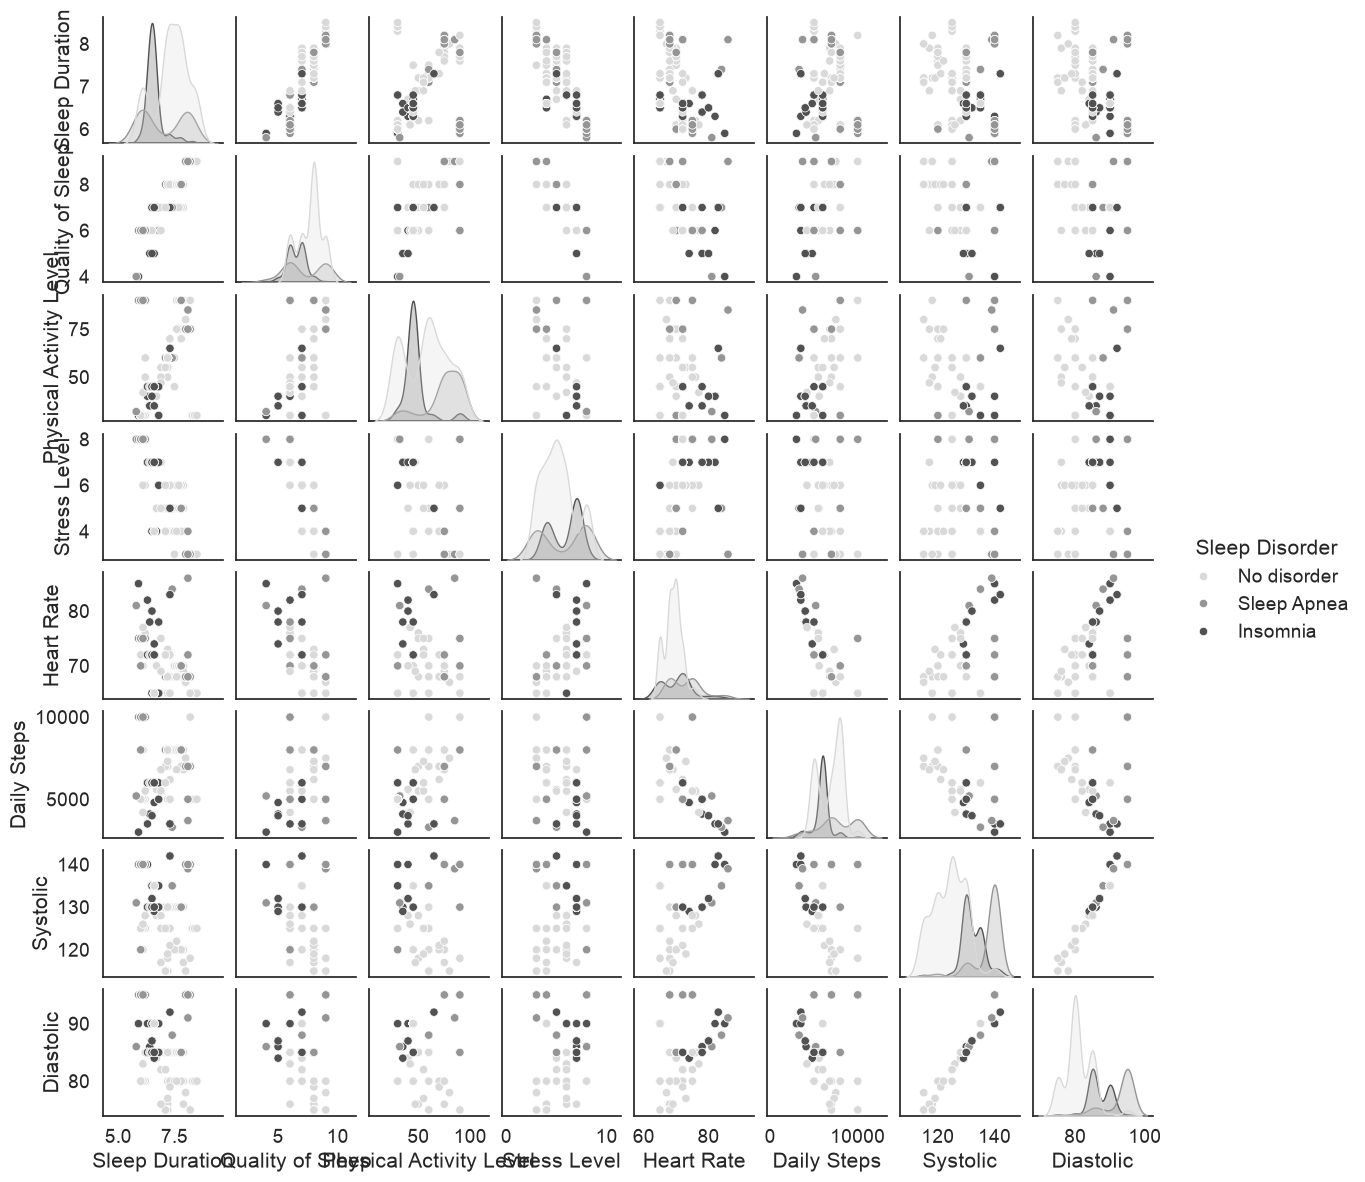

In [46]:
sns.pairplot(sleep_df.drop(['Person ID', 'Age', 'Blood Pressure'], axis=1), hue='Sleep Disorder', height=1.5, diag_kind='kde')
plt.xticks(rotation=90)
plt.show()
#show.set(xticklabels=[])

In [47]:
#create a copy of the dataset with a sample weight for each patient to balance the classes
from sklearn.utils.class_weight import compute_sample_weight

sleep_df_weight = sleep_df.copy()
sleep_df_weight['weight'] = compute_sample_weight(class_weight='balanced', y=sleep_df_weight['Sleep Disorder'])

sleep_df_weight.groupby('Sleep Disorder')['weight'].first()

Sleep Disorder
Insomnia       1.619048
No disorder    0.569254
Sleep Apnea    1.598291
Name: weight, dtype: float64

In [48]:
#checking shape of the resample dataset
sleep_df_weight.shape

(374, 17)

<Axes: xlabel='Sleep Disorder', ylabel='count'>

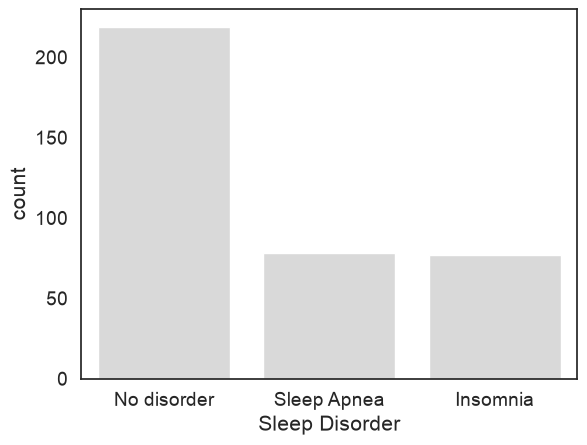

In [49]:
#checking class balance
sns.countplot(x='Sleep Disorder', data=sleep_df)

In [50]:
#print dataframe
sleep_df.head(3)

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic,Age_cat
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,No disorder,126,83,young_adult
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,No disorder,125,80,young_adult
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,No disorder,125,80,young_adult


In [51]:
#dropping irrelevant columns
pred_dt = sleep_df.drop(['Person ID','Age','Blood Pressure'], axis=1)
#checking for the variance of numeric data only
data = pred_dt.select_dtypes(exclude=['category','object'])
data.var()

Sleep Duration             6.330696e-01
Quality of Sleep           1.432703e+00
Physical Activity Level    4.339224e+02
Stress Level               3.148944e+00
Heart Rate                 1.710381e+01
Daily Steps                2.617651e+06
Systolic                   6.003333e+01
Diastolic                  3.796546e+01
dtype: float64

In [52]:
#using standard scaler for preprocessing of the data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

#creating the scaled dataframe as scaled_df
Columns = data.columns
scaled_df = pd.DataFrame(data=scaled_data, columns=Columns)
scaled_df

,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic
0,-1.298887,-1.098280,-0.825418,0.347021,1.654719,-1.619584,-0.330002,-0.268102
1,-1.173036,-1.098280,0.039844,1.475592,1.170474,1.970077,-0.459239,-0.755640
2,-1.173036,-1.098280,0.039844,1.475592,1.170474,1.970077,-0.459239,-0.755640
3,-1.550588,-2.771424,-1.402260,1.475592,3.591698,-2.362273,1.479309,0.869486
4,-1.550588,-2.771424,-1.402260,1.475592,3.591698,-2.362273,1.479309,0.869486
...,...,...,...,...,...,...,...,...
369,1.218127,1.411435,0.760896,-1.345836,-0.524383,0.113356,1.479309,1.682049
370,1.092276,1.411435,0.760896,-1.345836,-0.524383,0.113356,1.479309,1.682049
371,1.218127,1.411435,0.760896,-1.345836,-0.524383,0.113356,1.479309,1.682049
372,1.218127,1.411435,0.760896,-1.345836,-0.524383,0.113356,1.479309,1.682049


In [53]:
#checking variance after scaling
scaled_df.var()

Sleep Duration             1.002681
Quality of Sleep           1.002681
Physical Activity Level    1.002681
Stress Level               1.002681
Heart Rate                 1.002681
Daily Steps                1.002681
Systolic                   1.002681
Diastolic                  1.002681
dtype: float64

In [54]:
#converting categorical columns to int data type
cat_data = pred_dt.select_dtypes(exclude=['float','int'])

cat_data.drop(['Sleep Disorder'], axis=1, inplace=True)
cat_dummies = pd.get_dummies(cat_data).astype(int)
cat_dummies

,Gender_Female,Gender_Male,Occupation_Accountant,Occupation_Doctor,Occupation_Engineer,Occupation_Lawyer,Occupation_Manager,Occupation_Nurse,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Obese,BMI Category_Overweight,Age_cat_young_adult,Age_cat_middle_age,Age_cat_older_adult,Age_cat_elderlies
0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0
1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
2,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
3,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0
4,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1
370,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1
371,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1
372,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1


In [55]:
#concating the scaled numerical data and the categorical dummy dataset

new_dt = pd.concat([scaled_df, cat_dummies], axis=1)
new_dt.head()

,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic,Gender_Female,Gender_Male,...,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Obese,BMI Category_Overweight,Age_cat_young_adult,Age_cat_middle_age,Age_cat_older_adult,Age_cat_elderlies
0,-1.298887,-1.098280,-0.825418,0.347021,1.654719,-1.619584,-0.330002,-0.268102,0,1,...,0,1,0,0,0,1,1,0,0,0
1,-1.173036,-1.098280,0.039844,1.475592,1.170474,1.970077,-0.459239,-0.755640,0,1,...,0,0,0,1,0,0,1,0,0,0
2,-1.173036,-1.098280,0.039844,1.475592,1.170474,1.970077,-0.459239,-0.755640,0,1,...,0,0,0,1,0,0,1,0,0,0
3,-1.550588,-2.771424,-1.402260,1.475592,3.591698,-2.362273,1.479309,0.869486,0,1,...,0,0,0,0,1,0,1,0,0,0
4,-1.550588,-2.771424,-1.402260,1.475592,3.591698,-2.362273,1.479309,0.869486,0,1,...,0,0,0,0,1,0,1,0,0,0


<Axes: xlabel='Sleep Disorder', ylabel='count'>

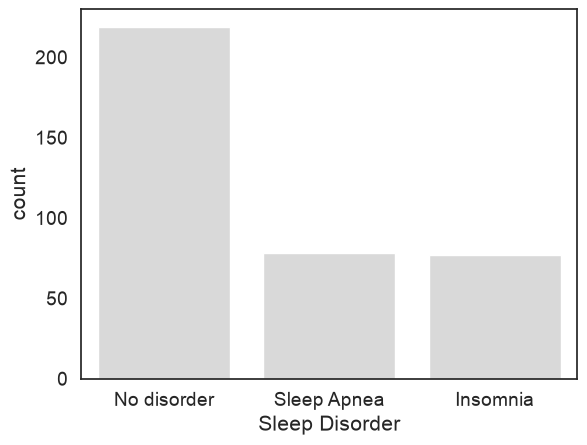

In [56]:
#checking class balance
sns.countplot(x='Sleep Disorder', data=sleep_df)

In [57]:
from imblearn.over_sampling import SMOTE

X = new_dt
y = sleep_df['Sleep Disorder']

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)


<Axes: xlabel='Sleep Disorder'>

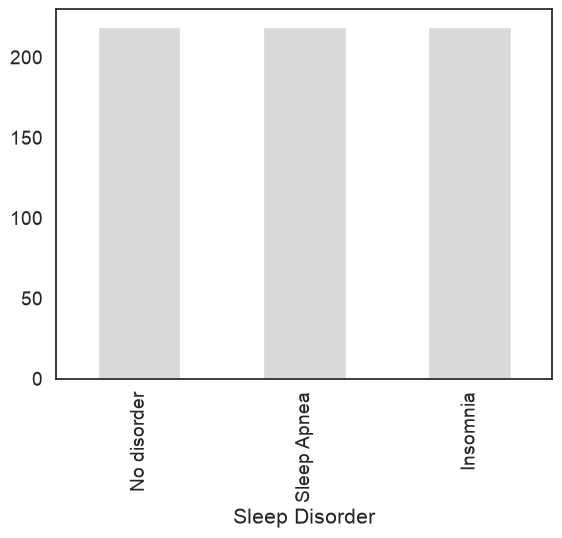

In [58]:
#checking class balance
y_resampled.value_counts().plot.bar()

In [59]:
#converting target variable to int data type

y = pd.get_dummies(y_resampled).astype('int')
y

,Insomnia,No disorder,Sleep Apnea
0,0,1,0
1,0,1,0
2,0,1,0
3,0,0,1
4,0,0,1
...,...,...,...
652,0,0,1
653,0,0,1
654,0,0,1
655,0,0,1


In [60]:
#Construct a classifier to predict the presence of a sleep disorder based on the other columns in the dataset.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_resampled, y, test_size=0.3, random_state=21, stratify=y)

print(X_resampled.shape)
print(y.shape)


(657, 28)
(657, 3)


In [61]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

Ir_model = OneVsRestClassifier(LogisticRegression())
Ir_model.fit(X_train, y_train)



OneVsRestClassifier(estimator=LogisticRegression())

In [62]:
Ir_model.classes_, Ir_model.multilabel_

(array([0, 1, 2]), True)

In [63]:
train_score = Ir_model.score(X_train,y_train)
print(train_score)

Ir_score = Ir_model.score(X_test,y_test)
print(Ir_score)

0.8997821350762527
0.9040404040404041


In [64]:
y_pred = Ir_model.predict(X_test) # For class labels

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

Ir_accuracy = accuracy_score(y_test, y_pred)
Ir_precision = precision_score(y_test, y_pred, average='micro') # 'micro' for multilabel/multiclass problems
Ir_recall = recall_score(y_test, y_pred, average='micro')
Ir_f1 = f1_score(y_test, y_pred, average='micro')
#cm = confusion_matrix(y_test, y_pred)

In [65]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

SVC_model = OneVsRestClassifier(LinearSVC())
SVC_model.fit(X_train, y_train)

OneVsRestClassifier(estimator=LinearSVC())

In [66]:
SVC_model.classes_, SVC_model.multilabel_

(array([0, 1, 2]), True)

In [67]:
train_score = SVC_model.score(X_train,y_train)
print(train_score)

Lsvc_score = SVC_model.score(X_test,y_test)
print(Lsvc_score)

0.9084967320261438
0.8939393939393939


In [68]:
y_pred = SVC_model.predict(X_test) # For class labels

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

Lsvc_accuracy = accuracy_score(y_test, y_pred)
Lsvc_precision = precision_score(y_test, y_pred, average='micro') # 'micro' for multilabel/multiclass problems
Lsvc_recall = recall_score(y_test, y_pred, average='micro')
Lsvc_f1 = f1_score(y_test, y_pred, average='micro')

In [69]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging1 = BaggingClassifier(estimator= DecisionTreeClassifier(random_state=42), max_samples = 0.5, max_features = 0.5,
                             bootstrap = False, bootstrap_features = False, random_state=42)

dt_model = OneVsRestClassifier(bagging1)
dt_model.fit(X_train, y_train)

bg_dt_score = dt_model.score(X_test, y_test)
print(bg_dt_score)

0.8838383838383839


In [70]:
y_pred = dt_model.predict(X_test) # For class labels

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

bg_dt_accuracy = accuracy_score(y_test, y_pred)
bg_dt_precision = precision_score(y_test, y_pred, average='micro') # 'micro' for multilabel/multiclass problems
bg_dt_recall = recall_score(y_test, y_pred, average='micro')
bg_dt_f1 = f1_score(y_test, y_pred, average='micro')

In [71]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(1000, 300, 300), solver='adam', shuffle=False, tol = 0.0001, random_state=42)

mlp_model = OneVsRestClassifier(mlp)
mlp_model.fit(X_train, y_train)

print("parameter: ", mlp_model.get_params())

mlp_score = mlp_model.score(X_test, y_test)
print(mlp_score)

parameter:  {'estimator__activation': 'relu', 'estimator__alpha': 0.0001, 'estimator__batch_size': 'auto', 'estimator__beta_1': 0.9, 'estimator__beta_2': 0.999, 'estimator__early_stopping': False, 'estimator__epsilon': 1e-08, 'estimator__hidden_layer_sizes': (1000, 300, 300), 'estimator__learning_rate': 'constant', 'estimator__learning_rate_init': 0.001, 'estimator__max_fun': 15000, 'estimator__max_iter': 200, 'estimator__momentum': 0.9, 'estimator__n_iter_no_change': 10, 'estimator__nesterovs_momentum': True, 'estimator__power_t': 0.5, 'estimator__random_state': 42, 'estimator__shuffle': False, 'estimator__solver': 'adam', 'estimator__tol': 0.0001, 'estimator__validation_fraction': 0.1, 'estimator__verbose': False, 'estimator__warm_start': False, 'estimator': MLPClassifier(hidden_layer_sizes=(1000, 300, 300), random_state=42,
              shuffle=False), 'n_jobs': None, 'verbose': 0}
0.9090909090909091


In [72]:
y_pred = mlp_model.predict(X_test) # For class labels

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

mlp_accuracy = accuracy_score(y_test, y_pred)
mlp_precision = precision_score(y_test, y_pred, average='micro') # 'micro' for multilabel/multiclass problems
mlp_recall = recall_score(y_test, y_pred, average='micro')
mlp_f1 = f1_score(y_test, y_pred, average='micro')

In [73]:
test_metrics = pd.DataFrame({
    'model':['Logistic_regression','LinearSVC','Bagging_DT Classifier','MLP Classifier'],
    'accuracy':[Ir_accuracy,Lsvc_accuracy,bg_dt_accuracy,mlp_accuracy],
    'precision':[Ir_precision,Lsvc_precision,bg_dt_precision,mlp_precision],
    'recall':[Ir_recall,Lsvc_recall,bg_dt_recall,mlp_recall],
    'f1':[Ir_f1,Lsvc_f1,bg_dt_f1,mlp_f1]
})

test_metrics.transpose().reset_index().rename(columns={'index':'metrics'})

,metrics,0,1,2,3
0,model,Logistic_regression,LinearSVC,Bagging_DT Classifier,MLP Classifier
1,accuracy,0.90404,0.893939,0.883838,0.909091
2,precision,0.919192,0.918782,0.91623,0.92
3,recall,0.919192,0.914141,0.883838,0.929293
4,f1,0.919192,0.916456,0.899743,0.924623


In [74]:
d = {'Model': ['Logistic Regression','LinearSVC', 'Bagging_decision tree based', 'MLP'],
     'accuracy' : [Ir_score, Lsvc_score, bg_dt_score, mlp_score]}

result_df = pd.DataFrame(data = d)
result_df = result_df.sort_values('accuracy',ascending=True)
result_df

,Model,accuracy
2,Bagging_decision tree based,0.883838
1,LinearSVC,0.893939
0,Logistic Regression,0.904040
3,MLP,0.909091


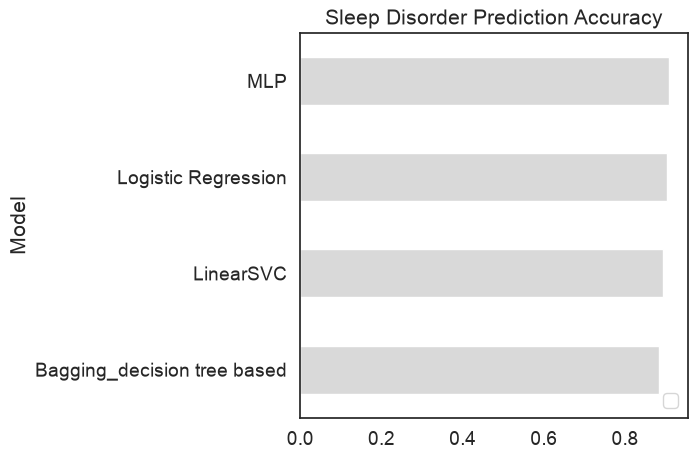

In [75]:
result_df.plot(x='Model', y='accuracy', kind='barh', figsize=(5,5), title='Sleep Disorder Prediction Accuracy')
plt.legend([])
plt.savefig('model_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

In [76]:
#Audit 1: how many rows are exact duplicates once Person ID is removed?
features = sleep_df.drop(columns=['Person ID'])
print('Duplicate rows (ignoring Person ID):', features.duplicated().sum(), 'of', len(features))
print('Unique patient profiles:', len(features.drop_duplicates()))

#Audit 2: how many test rows were created by SMOTE, and how many are exact copies of a training row?
synthetic_in_test = (X_test.index >= len(sleep_df)).sum()
train_rows = set(map(tuple, X_train.round(6).values))
copies_in_test = sum(tuple(row) in train_rows for row in X_test.round(6).values)
print('Test rows created by SMOTE:', synthetic_in_test, 'of', len(X_test))
print('Test rows identical to a training row:', copies_in_test, 'of', len(X_test))

Duplicate rows (ignoring Person ID): 242 of 374
Unique patient profiles: 132
Test rows created by SMOTE: 80 of 198
Test rows identical to a training row: 161 of 198


              precision    recall  f1-score   support

    Insomnia      0.826     0.826     0.826        23
 No disorder      0.923     0.909     0.916        66
 Sleep Apnea      0.800     0.833     0.816        24

    accuracy                          0.876       113
   macro avg      0.850     0.856     0.853       113
weighted avg      0.877     0.876     0.877       113



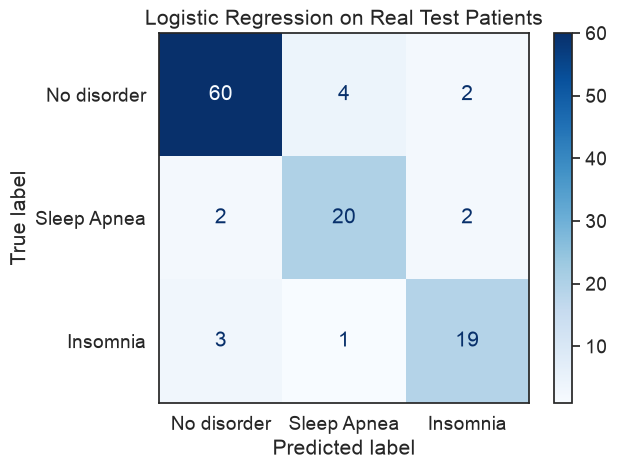

In [77]:
from imblearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

X_real = pd.concat([data, cat_dummies], axis=1)   #unscaled features; the pipeline scales them
y_real = sleep_df['Sleep Disorder']

honest_model = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(max_iter=1000))
])

X_tr, X_te, y_tr, y_te = train_test_split(X_real, y_real, test_size=0.3, random_state=21, stratify=y_real)
honest_model.fit(X_tr, y_tr)
y_pred_honest = honest_model.predict(X_te)

print(classification_report(y_te, y_pred_honest, digits=3))

labels = ['No disorder', 'Sleep Apnea', 'Insomnia']
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_honest, labels=labels), display_labels=labels).plot(cmap='Blues')
plt.title('Logistic Regression on Real Test Patients')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [78]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, recall_score

profile_id = X_real.astype(str).agg('|'.join, axis=1).factorize()[0]

cv_results = []
for name, cv, groups in [('Standard 5-fold CV', StratifiedKFold(5, shuffle=True, random_state=42), None),
                         ('Grouped 5-fold CV', StratifiedGroupKFold(5, shuffle=True, random_state=42), profile_id)]:
    preds = cross_val_predict(honest_model, X_real, y_real, cv=cv, groups=groups)
    recalls = recall_score(y_real, preds, average=None, labels=labels)
    cv_results.append([name, accuracy_score(y_real, preds)] + list(recalls))

#same model on the 132 unique profiles only
unique_df = X_real.assign(target=y_real).drop_duplicates()
X_u, y_u = unique_df.drop(columns='target'), unique_df['target']
preds = cross_val_predict(honest_model, X_u, y_u, cv=StratifiedKFold(5, shuffle=True, random_state=42))
cv_results.append(['Unique profiles only (132)', accuracy_score(y_u, preds)] + list(recall_score(y_u, preds, average=None, labels=labels)))

cv_df = pd.DataFrame(cv_results, columns=['Evaluation', 'Accuracy', 'Recall: No disorder', 'Recall: Sleep Apnea', 'Recall: Insomnia']).round(3)
cv_df

,Evaluation,Accuracy,Recall: No disorder,Recall: Sleep Apnea,Recall: Insomnia
0,Standard 5-fold CV,0.896,0.918,0.897,0.831
1,Grouped 5-fold CV,0.869,0.922,0.808,0.779
2,Unique profiles only (132),0.532,0.621,0.480,0.385


In [79]:
from sklearn.tree import DecisionTreeClassifier, export_text

simple_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_preds = cross_val_predict(simple_tree, X_real, y_real, cv=StratifiedGroupKFold(5, shuffle=True, random_state=42), groups=profile_id)
print('2-question tree, grouped CV accuracy:', round(accuracy_score(y_real, tree_preds), 3))
print(export_text(simple_tree.fit(X_real, y_real), feature_names=list(X_real.columns)))

2-question tree, grouped CV accuracy: 0.874
|--- BMI Category_Normal <= 0.50
|   |--- Physical Activity Level <= 70.00
|   |   |--- class: Insomnia
|   |--- Physical Activity Level >  70.00
|   |   |--- class: Sleep Apnea
|--- BMI Category_Normal >  0.50
|   |--- Quality of Sleep <= 5.50
|   |   |--- class: Insomnia
|   |--- Quality of Sleep >  5.50
|   |   |--- class: No disorder



In [80]:
apnea = sleep_df[sleep_df['Sleep Disorder'] == 'Sleep Apnea']
print('Sleep apnea patients who are female:', round((apnea['Gender'] == 'Female').mean() * 100, 1), '%')
print('Sleep apnea patients who are nurses:', round((apnea['Occupation'] == 'Nurse').mean() * 100, 1), '%')
print('\nAverage daily steps by group:')
print(sleep_df.groupby('Sleep Disorder')['Daily Steps'].mean().round(0))
print('\nSleep disorder rate by BMI category (%):')
pd.crosstab(sleep_df['BMI Category'], sleep_df['Sleep Disorder'], normalize='index').mul(100).round(1)

Sleep apnea patients who are female: 85.9 %
Sleep apnea patients who are nurses: 78.2 %

Average daily steps by group:
Sleep Disorder
Insomnia       5901.0
No disorder    6853.0
Sleep Apnea    7619.0
Name: Daily Steps, dtype: float64

Sleep disorder rate by BMI category (%):


Sleep Disorder,Insomnia,No disorder,Sleep Apnea
BMI Category,,,
Normal,4.2,92.6,3.2
Obese,40.0,0.0,60.0
Overweight,43.2,12.8,43.9


In [81]:
#Feature removal test: does the model rely on occupation, or on clinical measures?
occupation_cols = [c for c in X_real.columns if c.startswith('Occupation_')]
gender_cols = [c for c in X_real.columns if c.startswith('Gender_')]
clinical_cols = [c for c in X_real.columns if c.startswith(('BMI Category_', 'Systolic', 'Diastolic'))]

feature_sets = {
    'All features': X_real.columns,
    'Without occupation': X_real.columns.drop(occupation_cols),
    'Without occupation and gender': X_real.columns.drop(occupation_cols + gender_cols),
    'BMI and blood pressure only': clinical_cols
}

grouped_cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)
removal_results = []
for name, cols in feature_sets.items():
    preds = cross_val_predict(honest_model, X_real[cols], y_real, cv=grouped_cv, groups=profile_id)
    removal_results.append([name, len(cols), accuracy_score(y_real, preds)] + list(recall_score(y_real, preds, average=None, labels=labels)))

pd.DataFrame(removal_results, columns=['Features', 'Count', 'Accuracy', 'Recall: No disorder', 'Recall: Sleep Apnea', 'Recall: Insomnia']).round(3)

,Features,Count,Accuracy,Recall: No disorder,Recall: Sleep Apnea,Recall: Insomnia
0,All features,28,0.869,0.922,0.808,0.779
1,Without occupation,17,0.864,0.922,0.808,0.753
2,Without occupation and gender,15,0.882,0.918,0.859,0.805
3,BMI and blood pressure only,5,0.874,0.913,0.795,0.844
